In [9]:
!pip install torchvision

Disease categories found: ['1.Dry AMD', '10.Glaucoma', '11.Normal Fundus', '2.Wet AMD', '3.Mild DR', '4.Moderate DR', '5.Severe DR', '6.Proliferate DR', '7.Cataract', '8.Hypertensive Retinopathy', '9.Pathological Myopia']


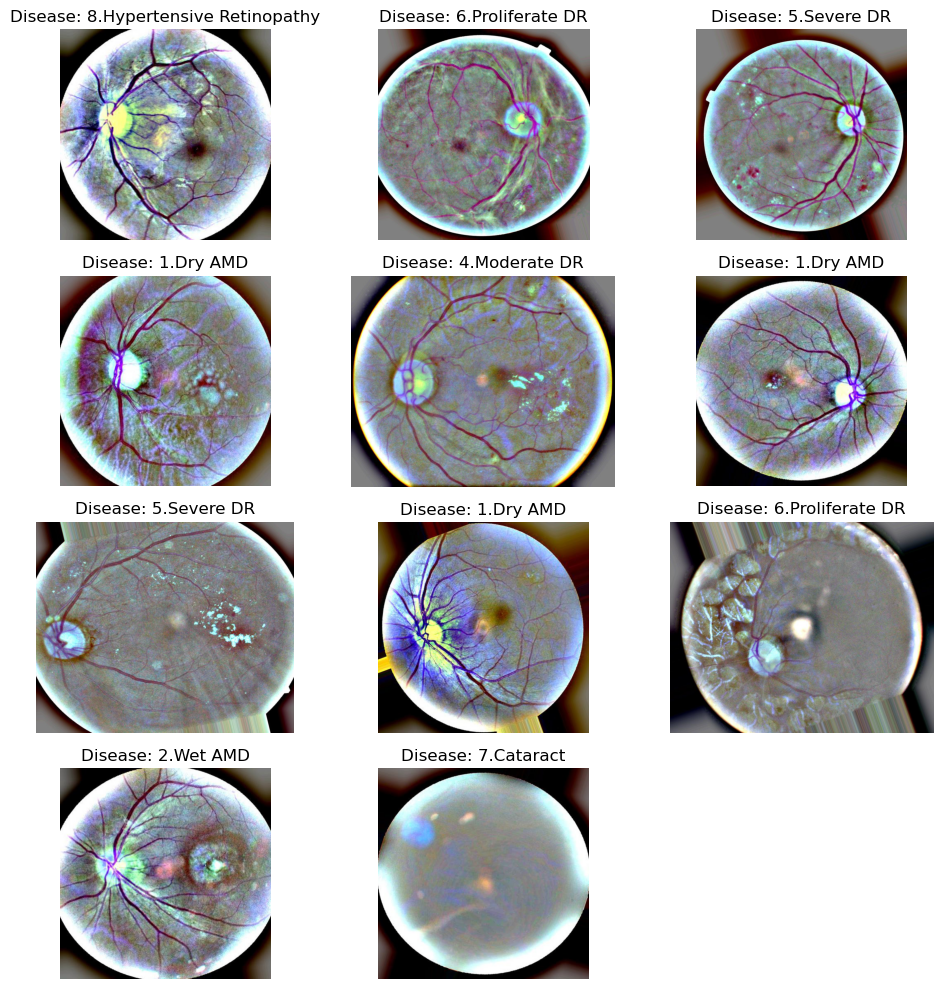

In [18]:
import os
import random
from PIL import Image
import matplotlib.pyplot as plt

train_dir = r'C:\Users\AIMSCS BT9\Downloads\archive (7)\Retinal Fundus Images\train'
diseases = os.listdir(train_dir)
print(f'Disease categories found: {diseases}')

num_images = 11
plt.figure(figsize=(10, 10))

for i in range(num_images):
    disease = random.choice(diseases)
    disease_path = os.path.join(train_dir, disease)
    img_name = random.choice(os.listdir(disease_path))
    img_path = os.path.join(disease_path, img_name)

    img = Image.open(img_path).convert('RGB')

    plt.subplot(4, 3, i + 1)
    plt.imshow(img)
    plt.title(f'Disease: {disease}')
    plt.axis('off')

plt.tight_layout()
plt.show()

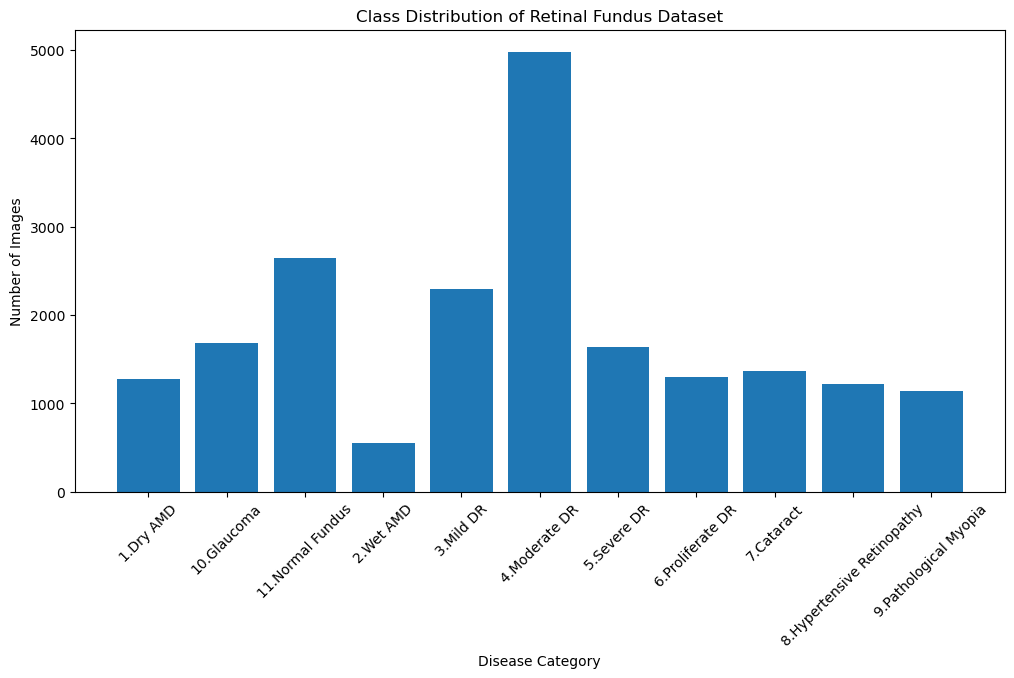

In [11]:
import matplotlib.pyplot as plt

disease_counts = {disease: len(os.listdir(os.path.join(train_dir, disease))) for disease in diseases}

plt.figure(figsize=(12, 6))
plt.bar(disease_counts.keys(), disease_counts.values())
plt.xticks(rotation=45)
plt.xlabel('Disease Category')
plt.ylabel('Number of Images')
plt.title('Class Distribution of Retinal Fundus Dataset')
plt.show()

In [12]:
train_dir = r'C:\Users\AIMSCS BT9\Downloads\archive (7)\Retinal Fundus Images\train'
image_sizes = set()

for disease in os.listdir(train_dir):
    disease_path = os.path.join(train_dir, disease)
    
    for img_name in os.listdir(disease_path):
        img_path = os.path.join(disease_path, img_name)
        
        try:
            img = Image.open(img_path)
            image_sizes.add(img.size)  # (width, height)
        except Exception as e:
            print(f"Error loading {img_path}: {e}")

print(f"Unique image sizes found: {image_sizes}")
print(f"Total unique sizes: {len(image_sizes)}")

Unique image sizes found: {(1024, 767), (1024, 776), (1024, 840), (1024, 785), (1024, 730), (1024, 849), (1024, 968), (1024, 794), (1024, 913), (1024, 739), (1024, 858), (1024, 977), (1024, 803), (1024, 922), (1024, 1041), (1024, 867), (1024, 931), (1024, 769), (1024, 833), (1024, 778), (1024, 897), (1024, 842), (1024, 787), (1024, 906), (1024, 1025), (1024, 851), (1024, 732), (1024, 796), (1024, 741), (1024, 860), (1024, 979), (1024, 805), (1024, 924), (1024, 933), (1024, 762), (1024, 826), (1024, 771), (1024, 890), (1024, 835), (1024, 954), (1024, 780), (1024, 899), (1024, 1018), (1024, 844), (1024, 963), (1024, 789), (1024, 908), (1024, 734), (1024, 1027), (1024, 972), (1024, 798), (1024, 917), (1024, 862), (1024, 926), (1024, 755), (1024, 725), (1024, 819), (1024, 764), (1024, 828), (1024, 947), (1024, 773), (1024, 892), (1024, 718), (1024, 837), (1024, 956), (1024, 782), (1024, 901), (1024, 1020), (1024, 727), (1024, 846), (1024, 791), (1024, 1029), (1024, 974), (1024, 684), (1024

Transformed Image Shape: torch.Size([3, 224, 224])


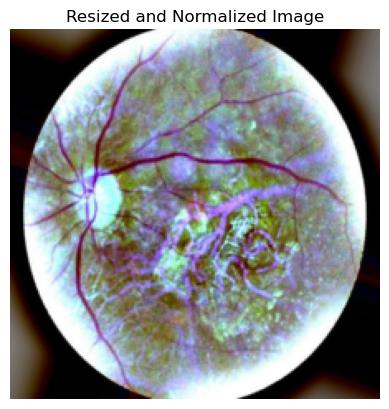

In [13]:
from torchvision import transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),              # Force all images to 224x224
    transforms.ToTensor(),                     # Convert to tensor (C, H, W) and normalize [0,1]
    transforms.Normalize([0.5, 0.5, 0.5],      # Standardize to [-1, 1]
                         [0.5, 0.5, 0.5])
])

# Example usage on a random image
sample_image_path = r'C:\Users\AIMSCS BT9\Downloads\archive (7)\Retinal Fundus Images\train\1.Dry AMD\Dry AMD43_right_0_180.jpeg'

img = Image.open(sample_image_path).convert('RGB')
img_transformed = transform(img)

print(f'Transformed Image Shape: {img_transformed.shape}')  # torch.Size([3, 224, 224])

# Visualize transformed image
plt.imshow(img_transformed.permute(1, 2, 0) * 0.5 + 0.5)  # Undo normalization for display
plt.title('Resized and Normalized Image')
plt.axis('off')
plt.show()

In [14]:
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder

# Set up dataset and loader
dataset = ImageFolder(root=train_dir, transform=transform)
loader = DataLoader(dataset, batch_size=8, shuffle=True)

# Get one batch
images, labels = next(iter(loader))

print(f"Batch shape: {images.shape}") 

Batch shape: torch.Size([8, 3, 224, 224])
